# 02 - Data Preprocessing & Splitting
## Metro Train Air Compressor - Failure Prediction

This notebook covers:
- Data cleaning and redundant column removal
- Failure labeling (pre-failure windows)
- Feature engineering (rolling window statistics)
- Time-based train/test split
- Save processed data for modeling

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime, timedelta
import os

pd.set_option('display.max_columns', None)
plt.style.use('seaborn-v0_8-whitegrid')
%matplotlib inline

# Create output directory
os.makedirs('../data/processed', exist_ok=True)

## 1. Load Data

In [2]:
# Load raw data
DATA_PATH = '../dataset/metropt+3+dataset/MetroPT3(AirCompressor).csv'
df = pd.read_csv(DATA_PATH)

# Parse timestamp
df['timestamp'] = pd.to_datetime(df['timestamp'])
df = df.set_index('timestamp')

# Drop the unnamed index column
df = df.drop(columns=['Unnamed: 0'])

print(f"Loaded {len(df):,} records")
print(f"Time range: {df.index.min()} to {df.index.max()}")
print(f"Columns: {list(df.columns)}")

Loaded 1,516,948 records
Time range: 2020-02-01 00:00:00 to 2020-09-01 03:59:50
Columns: ['TP2', 'TP3', 'H1', 'DV_pressure', 'Reservoirs', 'Oil_temperature', 'Motor_current', 'COMP', 'DV_eletric', 'Towers', 'MPG', 'LPS', 'Pressure_switch', 'Oil_level', 'Caudal_impulses']


## 2. Define Failure Periods

In [3]:
# Known failure periods from documentation
FAILURE_PERIODS = [
    {"id": 1, "start": "2020-04-18 00:00:00", "end": "2020-04-18 23:59:00", "type": "Air Leak"},
    {"id": 2, "start": "2020-05-29 23:30:00", "end": "2020-05-30 06:00:00", "type": "Air Leak"},
    {"id": 3, "start": "2020-06-05 10:00:00", "end": "2020-06-07 14:30:00", "type": "Air Leak"},
    {"id": 4, "start": "2020-07-15 14:30:00", "end": "2020-07-15 19:00:00", "type": "Air Leak"},
]

failure_df = pd.DataFrame(FAILURE_PERIODS)
failure_df['start'] = pd.to_datetime(failure_df['start'])
failure_df['end'] = pd.to_datetime(failure_df['end'])
failure_df['duration'] = failure_df['end'] - failure_df['start']

print("Failure Periods:")
failure_df

Failure Periods:


,id,start,end,type,duration
0,1,2020-04-18 00:00:00,2020-04-18 23:59:00,Air Leak,0 days 23:59:00
1,2,2020-05-29 23:30:00,2020-05-30 06:00:00,Air Leak,0 days 06:30:00
2,3,2020-06-05 10:00:00,2020-06-07 14:30:00,Air Leak,2 days 04:30:00
3,4,2020-07-15 14:30:00,2020-07-15 19:00:00,Air Leak,0 days 04:30:00


## 3. Data Cleaning

In [4]:
# Check correlation between TP3 and Reservoirs (from EDA: 100% correlated)
corr = df['TP3'].corr(df['Reservoirs'])
print(f"Correlation TP3 <-> Reservoirs: {corr:.4f}")

# Drop Reservoirs (redundant)
df = df.drop(columns=['Reservoirs'])
print(f"\nDropped 'Reservoirs' column (redundant with TP3)")
print(f"Remaining columns: {len(df.columns)}")

Correlation TP3 <-> Reservoirs: 1.0000

Dropped 'Reservoirs' column (redundant with TP3)
Remaining columns: 14


In [5]:
# Define signal groups
ANALOGUE_SIGNALS = ['TP2', 'TP3', 'H1', 'DV_pressure', 'Motor_current', 'Oil_temperature']
DIGITAL_SIGNALS = ['COMP', 'DV_eletric', 'Towers', 'MPG', 'LPS', 'Pressure_switch', 'Oil_level', 'Caudal_impulses']

print(f"Analogue signals ({len(ANALOGUE_SIGNALS)}): {ANALOGUE_SIGNALS}")
print(f"Digital signals ({len(DIGITAL_SIGNALS)}): {DIGITAL_SIGNALS}")

Analogue signals (6): ['TP2', 'TP3', 'H1', 'DV_pressure', 'Motor_current', 'Oil_temperature']
Digital signals (8): ['COMP', 'DV_eletric', 'Towers', 'MPG', 'LPS', 'Pressure_switch', 'Oil_level', 'Caudal_impulses']


## 4. Create Failure Labels

We create labels for:
- **failure**: Currently in a failure period (1 = failure, 0 = normal)
- **pre_failure**: Within X hours before a failure (for prediction)

The `PRE_FAILURE_HORIZON` is configurable - this is how early we want to predict.

In [6]:
# Configuration: Pre-failure prediction horizon
PRE_FAILURE_HORIZON_HOURS = 2  # Predict failure 2 hours ahead

def create_labels(df, failure_df, pre_failure_hours=2):
    """
    Create failure and pre-failure labels.
    
    Args:
        df: DataFrame with timestamp index
        failure_df: DataFrame with failure periods (start, end columns)
        pre_failure_hours: Hours before failure to label as pre-failure
    
    Returns:
        DataFrame with added 'failure' and 'pre_failure' columns
    """
    df = df.copy()
    
    # Initialize labels
    df['failure'] = 0
    df['pre_failure'] = 0
    df['failure_id'] = 0  # Track which failure event
    
    for _, row in failure_df.iterrows():
        # Label failure period
        mask_failure = (df.index >= row['start']) & (df.index <= row['end'])
        df.loc[mask_failure, 'failure'] = 1
        df.loc[mask_failure, 'failure_id'] = row['id']
        
        # Label pre-failure period (X hours before failure start)
        pre_failure_start = row['start'] - pd.Timedelta(hours=pre_failure_hours)
        mask_pre_failure = (df.index >= pre_failure_start) & (df.index < row['start'])
        df.loc[mask_pre_failure, 'pre_failure'] = 1
        df.loc[mask_pre_failure, 'failure_id'] = row['id']
    
    return df

# Apply labeling
df = create_labels(df, failure_df, pre_failure_hours=PRE_FAILURE_HORIZON_HOURS)

print(f"Pre-failure horizon: {PRE_FAILURE_HORIZON_HOURS} hours")
print(f"\nLabel distribution:")
print(f"  Normal:      {(df['failure'] == 0).sum():,} ({(df['failure'] == 0).mean()*100:.2f}%)")
print(f"  Failure:     {(df['failure'] == 1).sum():,} ({(df['failure'] == 1).mean()*100:.2f}%)")
print(f"  Pre-failure: {(df['pre_failure'] == 1).sum():,} ({(df['pre_failure'] == 1).mean()*100:.2f}%)")

Pre-failure horizon: 2 hours

Label distribution:
  Normal:      1,486,994 (98.03%)
  Failure:     29,954 (1.97%)
  Pre-failure: 2,776 (0.18%)


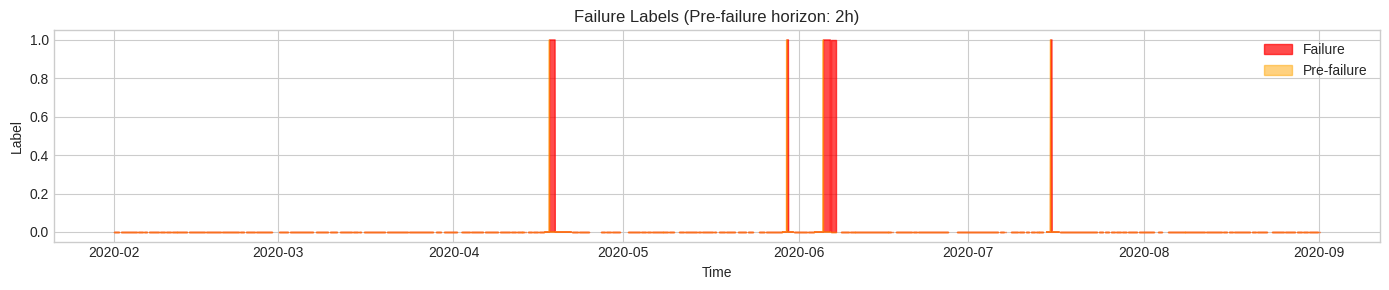

In [7]:
# Visualize labels on timeline
fig, ax = plt.subplots(figsize=(14, 3))

# Plot labels
plot_df = df.resample('1h').max()  # Hourly max for visualization
ax.fill_between(plot_df.index, 0, plot_df['failure'], alpha=0.7, color='red', label='Failure')
ax.fill_between(plot_df.index, 0, plot_df['pre_failure'], alpha=0.5, color='orange', label='Pre-failure')

ax.set_ylabel('Label')
ax.set_xlabel('Time')
ax.set_title(f'Failure Labels (Pre-failure horizon: {PRE_FAILURE_HORIZON_HOURS}h)')
ax.legend()
plt.tight_layout()
plt.show()

## 5. Feature Engineering

Create rolling window features to capture temporal patterns:
- Rolling mean, std, min, max
- Rolling slope/trend
- Rate of change

In [8]:
# Configuration: Window sizes
WINDOW_SIZES = [60, 300, 600]  # ~10min, ~50min, ~100min (in samples, data is ~10s intervals)

def create_rolling_features(df, signals, window_sizes):
    """
    Create rolling window features for specified signals.
    
    Features created per signal per window:
    - mean, std, min, max
    - range (max - min)
    """
    df = df.copy()
    
    for signal in signals:
        for window in window_sizes:
            prefix = f"{signal}_w{window}"
            
            # Rolling statistics
            rolling = df[signal].rolling(window=window, min_periods=1)
            
            df[f"{prefix}_mean"] = rolling.mean()
            df[f"{prefix}_std"] = rolling.std().fillna(0)
            df[f"{prefix}_min"] = rolling.min()
            df[f"{prefix}_max"] = rolling.max()
            df[f"{prefix}_range"] = df[f"{prefix}_max"] - df[f"{prefix}_min"]
    
    return df

print(f"Creating rolling features for {len(ANALOGUE_SIGNALS)} signals with windows {WINDOW_SIZES}...")
df = create_rolling_features(df, ANALOGUE_SIGNALS, WINDOW_SIZES)

# Count new features
n_new_features = len(ANALOGUE_SIGNALS) * len(WINDOW_SIZES) * 5
print(f"Created {n_new_features} new rolling features")
print(f"Total columns: {len(df.columns)}")

Creating rolling features for 6 signals with windows [60, 300, 600]...
Created 90 new rolling features
Total columns: 107


In [9]:
# Add rate of change features
def create_rate_of_change(df, signals, periods=[10, 60]):
    """Create rate of change (difference) features."""
    df = df.copy()
    
    for signal in signals:
        for period in periods:
            df[f"{signal}_roc_{period}"] = df[signal].diff(periods=period)
    
    return df

df = create_rate_of_change(df, ANALOGUE_SIGNALS)
print(f"Added rate of change features")
print(f"Total columns: {len(df.columns)}")

Added rate of change features
Total columns: 119


In [10]:
# Fill NaN values created by rolling/diff operations
nan_before = df.isnull().sum().sum()
df = df.fillna(method='bfill').fillna(method='ffill').fillna(0)
nan_after = df.isnull().sum().sum()

print(f"NaN values: {nan_before:,} -> {nan_after:,}")

/tmp/ipykernel_30704/2954275064.py:3: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df = df.fillna(method='bfill').fillna(method='ffill').fillna(0)


NaN values: 420 -> 0


## 6. Time-Based Train/Test Split

**Critical:** We use time-based splits to avoid data leakage.
- Never use random splits (adjacent samples are near-duplicates)
- Train on earlier data, test on later data
- Ensure each split has failure examples

In [11]:
# Time-based split strategy
# Training: Feb - May (failures #1, #2)
# Validation: June (failure #3) 
# Test: July - Aug (failure #4)

TRAIN_END = '2020-05-31 23:59:59'
VAL_END = '2020-06-30 23:59:59'

train_df = df[df.index <= TRAIN_END].copy()
val_df = df[(df.index > TRAIN_END) & (df.index <= VAL_END)].copy()
test_df = df[df.index > VAL_END].copy()

print("Time-based Split:")
print(f"  Train: {train_df.index.min().date()} to {train_df.index.max().date()} ({len(train_df):,} samples)")
print(f"  Val:   {val_df.index.min().date()} to {val_df.index.max().date()} ({len(val_df):,} samples)")
print(f"  Test:  {test_df.index.min().date()} to {test_df.index.max().date()} ({len(test_df):,} samples)")

Time-based Split:
  Train: 2020-02-01 to 2020-05-31 (856,832 samples)
  Val:   2020-06-01 to 2020-06-30 (216,514 samples)
  Test:  2020-07-01 to 2020-09-01 (443,602 samples)


In [12]:
# Check failure distribution in each split
print("\nFailure distribution:")
for name, split_df in [('Train', train_df), ('Val', val_df), ('Test', test_df)]:
    n_failure = (split_df['failure'] == 1).sum()
    n_pre_failure = (split_df['pre_failure'] == 1).sum()
    failure_ids = split_df[split_df['failure_id'] > 0]['failure_id'].unique()
    print(f"  {name}: {n_failure:,} failure, {n_pre_failure:,} pre-failure samples (failures: {list(failure_ids)})")


Failure distribution:
  Train: 11,017 failure, 1,324 pre-failure samples (failures: [np.int64(1), np.int64(2)])
  Val: 17,315 failure, 726 pre-failure samples (failures: [np.int64(3)])
  Test: 1,622 failure, 726 pre-failure samples (failures: [np.int64(4)])


/tmp/ipykernel_30704/1904843238.py:8: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  resampled = split_df['TP2'].resample('1H').mean()


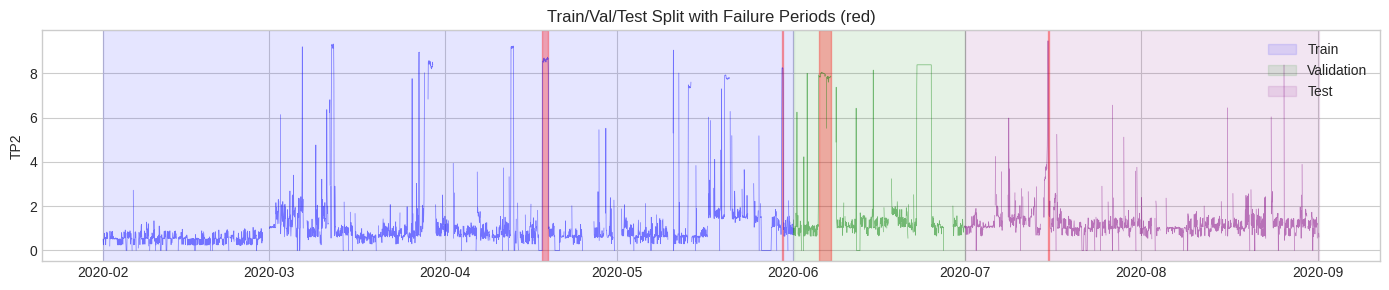

In [13]:
# Visualize the split
fig, ax = plt.subplots(figsize=(14, 3))

# Plot each split
for split_df, color, label in [(train_df, 'blue', 'Train'), 
                                (val_df, 'green', 'Validation'),
                                (test_df, 'purple', 'Test')]:
    resampled = split_df['TP2'].resample('1H').mean()
    ax.plot(resampled.index, resampled.values, color=color, alpha=0.5, linewidth=0.5)
    ax.axvspan(split_df.index.min(), split_df.index.max(), alpha=0.1, color=color, label=label)

# Mark failures
for _, row in failure_df.iterrows():
    ax.axvspan(row['start'], row['end'], alpha=0.3, color='red')

ax.set_ylabel('TP2')
ax.set_title('Train/Val/Test Split with Failure Periods (red)')
ax.legend(loc='upper right')
plt.tight_layout()
plt.show()

## 7. Normalization

Fit scaler on training data only to prevent data leakage.

In [14]:
from sklearn.preprocessing import StandardScaler

# Get feature columns (exclude labels and metadata)
label_cols = ['failure', 'pre_failure', 'failure_id']
feature_cols = [col for col in df.columns if col not in label_cols]

print(f"Feature columns: {len(feature_cols)}")
print(f"Label columns: {label_cols}")

Feature columns: 116
Label columns: ['failure', 'pre_failure', 'failure_id']


In [15]:
# Fit scaler on training data only
scaler = StandardScaler()
scaler.fit(train_df[feature_cols])

# Transform all splits
train_scaled = train_df.copy()
val_scaled = val_df.copy()
test_scaled = test_df.copy()

train_scaled[feature_cols] = scaler.transform(train_df[feature_cols])
val_scaled[feature_cols] = scaler.transform(val_df[feature_cols])
test_scaled[feature_cols] = scaler.transform(test_df[feature_cols])

print("Normalization complete (fitted on training data only)")

Normalization complete (fitted on training data only)


## 8. Save Processed Data

In [16]:
# Save to parquet (efficient format)
train_scaled.to_parquet('../data/processed/train.parquet')
val_scaled.to_parquet('../data/processed/val.parquet')
test_scaled.to_parquet('../data/processed/test.parquet')

# Save scaler
import joblib
joblib.dump(scaler, '../data/processed/scaler.joblib')

# Save feature list
with open('../data/processed/features.txt', 'w') as f:
    f.write('\n'.join(feature_cols))

print("Saved:")
print("  - data/processed/train.parquet")
print("  - data/processed/val.parquet")
print("  - data/processed/test.parquet")
print("  - data/processed/scaler.joblib")
print("  - data/processed/features.txt")

Saved:
  - data/processed/train.parquet
  - data/processed/val.parquet
  - data/processed/test.parquet
  - data/processed/scaler.joblib
  - data/processed/features.txt


## 9. Summary

### Preprocessing Complete

**Data Cleaning:**
- Dropped `Reservoirs` column (100% correlated with TP3)
- No missing values in original data

**Feature Engineering:**
- Rolling window features (mean, std, min, max, range) for 3 window sizes
- Rate of change features
- Total features: 100+

**Labels Created:**
- `failure`: Binary label for failure periods
- `pre_failure`: Binary label for pre-failure window (2 hours before)
- `failure_id`: Which failure event (1-4)

**Time-Based Split:**
- Train: Feb-May (failures #1, #2)
- Validation: June (failure #3)
- Test: July-Aug (failure #4)

**Next Steps:**
1. Baseline models (`03_baseline_models.ipynb`)
2. Advanced models (`04_advanced_models.ipynb`)